# Calculate metrics using climpred

---

Now that all of our model and observational data is ready for analysis, we can run this notebook and calculate various metrics using climpred for each model, for one season at a time, and compare how they do. It is recommended that you use `dask` to run this notebook as we are looking at geospatial data and making maps. Start the `dask` cluster first by running `cluster.ipynb`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os

import numpy as np
import pandas as pd
import xarray as xr
xr.set_options(keep_attrs=True)
import climpred
import cartopy.crs as ccrs
import intake
import matplotlib.pyplot as plt
import ultraplot as uplt

import dask.config
dask.config.set({"array.slicing.split_large_chunks": False})

- Connect to the shared `dask` cluster (start it first by running `cluster.ipynb`).

In [2]:
from dask_cluster import get_client
client = get_client()

In [3]:
savefig = "no" #yes or no
plotdir = "plots/"
os.makedirs(plotdir, exist_ok=True)

## Here is where you choose your variable, metric and start/end time.

In [ ]:
variable = ["t2m","tp","gh_500","psl"] #can be t2m, tp, gh_500, psl
metric = "acc" #can be acc, rmse, msess_murphy (rps/rpss need category edge files, not loaded here)
predict = "hindcast" #can be perfect or hindcast
data = "anom"
lead = "biweekly" #biweekly or daily
area = "geospatial"
start = "1999-01-01"
end = "2022-12-31"
season = "DJF" # JJA, DJF, ann
modeln = {"MPAS_60km": "MPAS 60km","MPAS_120km": "MPAS 120km","CAM6_ERA5": "CAM6","CESM2_ERA5": "CESM2"} #Models from cat, then name you want displayed on plot
models = list(modeln.keys())
domain = "global" #can be global or namerica

In [5]:
plot_settings = {"acc":  {"t2m": {"vmin": 0.0,"vmax": 1.0,"cmap": "OrRd"},
                          "tp": {"vmin": 0.0,"vmax": 0.7,"cmap": "OrRd"},
                          "default": {"vmin": 0.0,"vmax": 1.0,"cmap": "OrRd",
                                      "comp": "e2o","dim": "init","ens": "ensmean"},},
                 "rmse": {"psl": {"vmin": 0.0,"vmax": 500.0,"cmap": "viridis"},
                          "gh_500": {"vmin": 0.0,"vmax": 75.0,"cmap": "viridis"},
                          "default": {"vmin": 0.0,"vmax": 5.0,"cmap": "viridis",
                                     "comp": "e2o","dim": "init","ens": "ensmean"},},
                 "msess_murphy": {"default": {"vmin": -1.0,"vmax": 1.0,"cmap": "RdBu_r",
                                  "comp": "e2o","dim": "init","ens": "ensmean",
                                  "dmin": -1.0,"dmax": 1.0},},}

ms = plot_settings.get(metric,{}).get("default",{})

## Now we read in and load the data into `dask`

We are using the intake catalog to find the data and load it up. The catalog is at located in this directory.

In [6]:
cat = intake.open_catalog("s2s_data_catalog.yml")

In [7]:
hinds = {}
for m in models:
    hinds[m] = cat[m](data=data, lead=lead, dim=area).to_dask()[variable].astype("float32")
    if domain == "namerica":
        hinds[m] = hinds[m].sel(lat=slice(15.0, 75.0),lon=slice(190.0, 305.0))
verif = cat["OBS_ERA5"](data=data, lead=lead, dim=area).to_dask()[variable].astype("float32")
if domain == "namerica":
    verif = verif.sel(lat=slice(15.0, 75.0),lon=slice(190.0, 305.0))

- All of the model data is now loaded into a dictionary so that we can have them all together for comparison purposes.

In [8]:
# is seasonal data available for all models and rechunk
for h in hinds:
    print(hinds[h].init.dt.season.to_index().unique(),"freq =",hinds[h].init.to_index().freq)
    hinds[h] = hinds[h].chunk({"member": -1, "init": -1, "lead": -1, "lat": 45, "lon": 60}).persist()
    hinds[h] = hinds[h].sel(init=slice(start,end))
    hinds[h] = hinds[h].where(-88.6<hinds[h].lat)
    hinds[h] = hinds[h].where(88.6>hinds[h].lat)
verif = verif.sel(time=slice(start,str(pd.to_datetime(end)+pd.DateOffset(days=46))))
verif = verif.chunk({"time": -1, "lat": 45, "lon": 60})

Index(['DJF', 'MAM', 'JJA', 'SON'], dtype='object', name='init') freq = 7D
Index(['DJF', 'MAM', 'JJA', 'SON'], dtype='object', name='init') freq = 7D
Index(['DJF', 'MAM', 'JJA', 'SON'], dtype='object', name='init') freq = 7D
Index(['DJF', 'MAM', 'JJA', 'SON'], dtype='object', name='init') freq = 7D


In [9]:
lmask = xr.open_dataset("lmask_360x181.nc")["lmask"]

## Create a Hindcast Ensemble in climpred for each of the models and run metrics

We are also setting kwargs (options) for `verify` in climpred. The second cell does the metric calculation using `verify` and computes it. Finally all models are concatenated together and plotted.

This could take a few minutes to run. If you are curious, check out the `dask` dashboard and you can watch the progress of the computations. The link should be like this: `https://jupyterhub.hpc.ucar.edu/stable/user/<username>/proxy/<port>/status`. Run `client.dashboard_link` to get it.

In [ ]:
he = {}
met = {}; met_all = {}
spr = {}; spr_all = {}
for h in hinds:
    print(h)
    # Work on a copy so hinds keeps the data as loaded: re-running this cell
    # (e.g. with a different season) then works without reloading.
    hind = hinds[h].copy()
    if season=="JJA":
        hind = hind.where(hind.init.dt.month.isin([6,7,8]),drop=True)
    elif season=="DJF":
        hind = hind.where(hind.init.dt.month.isin([1,2,12]),drop=True)

    hind["t2m"] = hind.t2m.where(lmask==False); hind["tp"] = hind.tp.where(lmask==False)
    # Leads are stored as time spans (1, 15, 29 days); convert to integer days.
    # This works for models with 2 biweekly periods (RR) or 3.
    if np.issubdtype(hind.lead.dtype, np.timedelta64):
        hind["lead"] = (hind.lead / np.timedelta64(1, "D")).astype(int)
    hind["lead"].attrs["units"] = 'days'
    
    if predict == "perfect":
        he[h] = climpred.PerfectModelEnsemble(hind)
        metric_kwargs = dict(metric=metric,comparison="e2c",dim=ms.get("dim"),
                             alignment="same_inits",reference=None,skipna=True)
    elif predict == "hindcast":
        he[h] = climpred.HindcastEnsemble(hind).add_observations(verif)
        metric_kwargs = dict(metric=metric,comparison=ms.get("comp"),dim=ms.get("dim"),
                             alignment="same_inits",reference=None,skipna=True)
    met[h] = he[h].verify(**metric_kwargs)
    met[h] = met[h].compute()
    if metric=="rmse":
        spr[h] = hind.std("member").mean("init")
        spr[h] = spr[h].compute()

if metric == "crps":
    met_all = xr.concat([met[m].mean("init") for m in models], dim="model").assign_coords(model=models)
else:
    met_all = xr.concat([met[m] for m in models], dim="model").assign_coords(model=models)
if metric=="rmse":
    spr_all = xr.concat([spr[m] for m in models], dim="model").assign_coords(model=models)

## Area weighting

Next we run cosine area weighting over the data to get a weighted lat/lon average over the domain (north of 60°S). These averages are printed on the maps and plotted on bar charts to compare the models.

In [11]:
# area weighting
# For acc, to zero out values below zero instead: met_wt = met_all.where((met_all > 0.0) & (met_all.lat > -60.0))
met_wt = met_all.where(met_all.lat>-60.0)
weight = met_wt.weighted(np.cos(np.deg2rad(met_wt.lat))).mean(("lat","lon")).compute()

t2m
tp
gh_500
psl


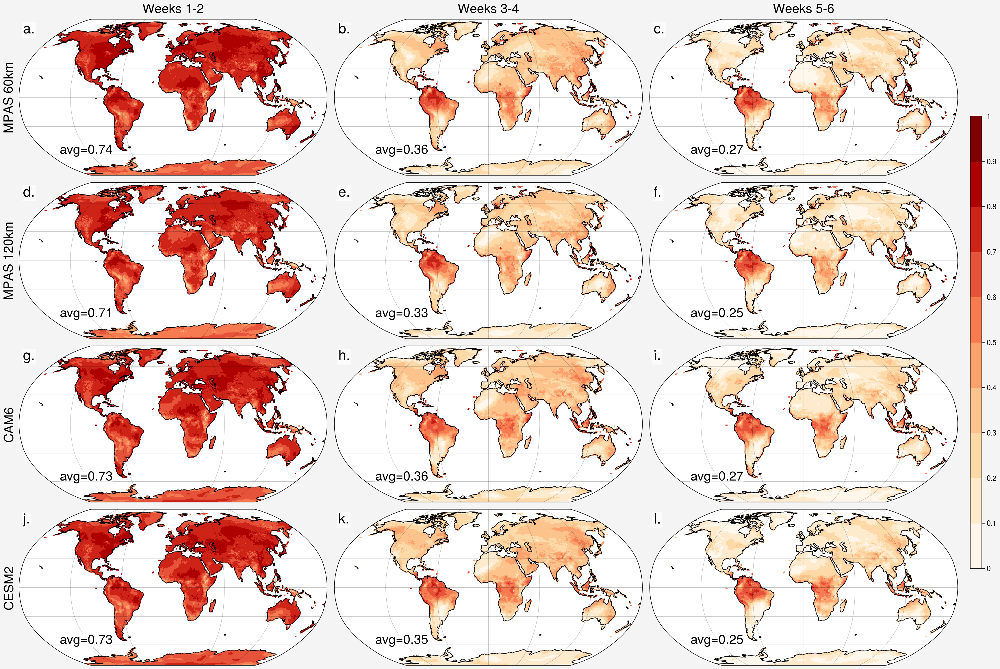

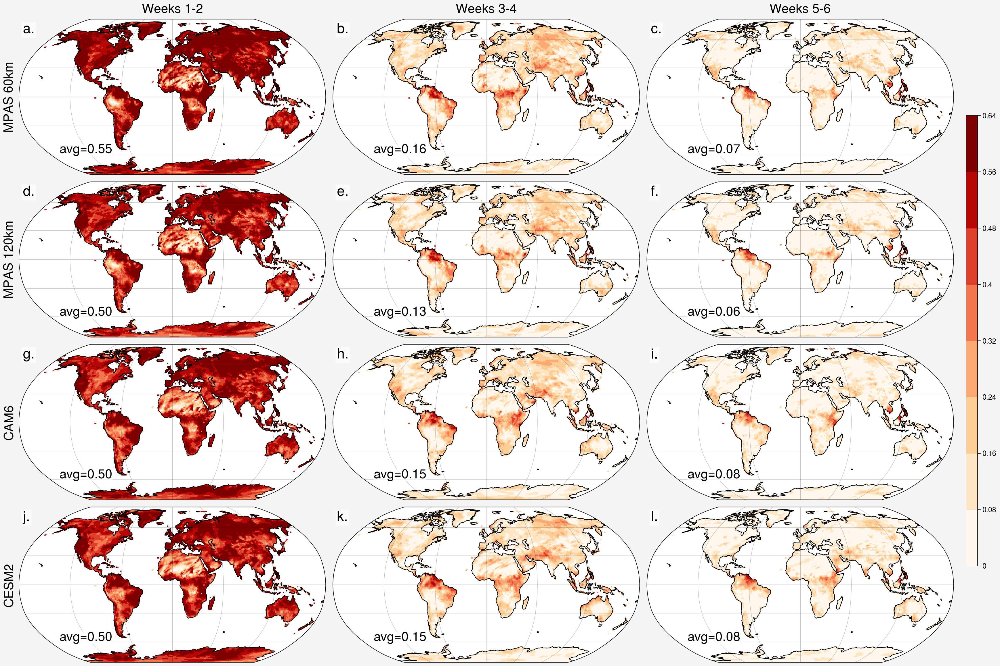

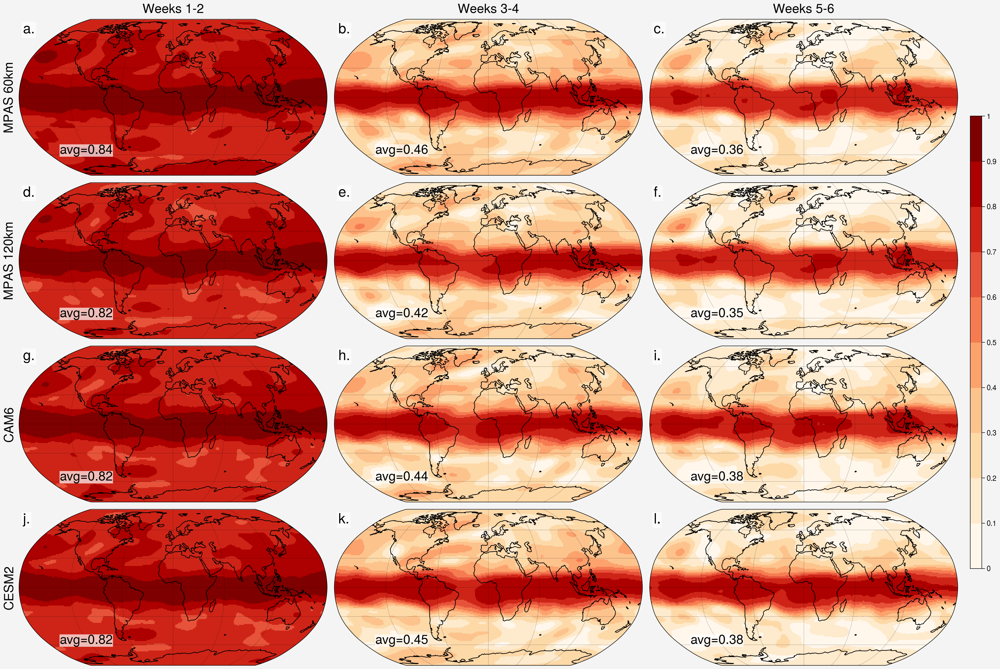

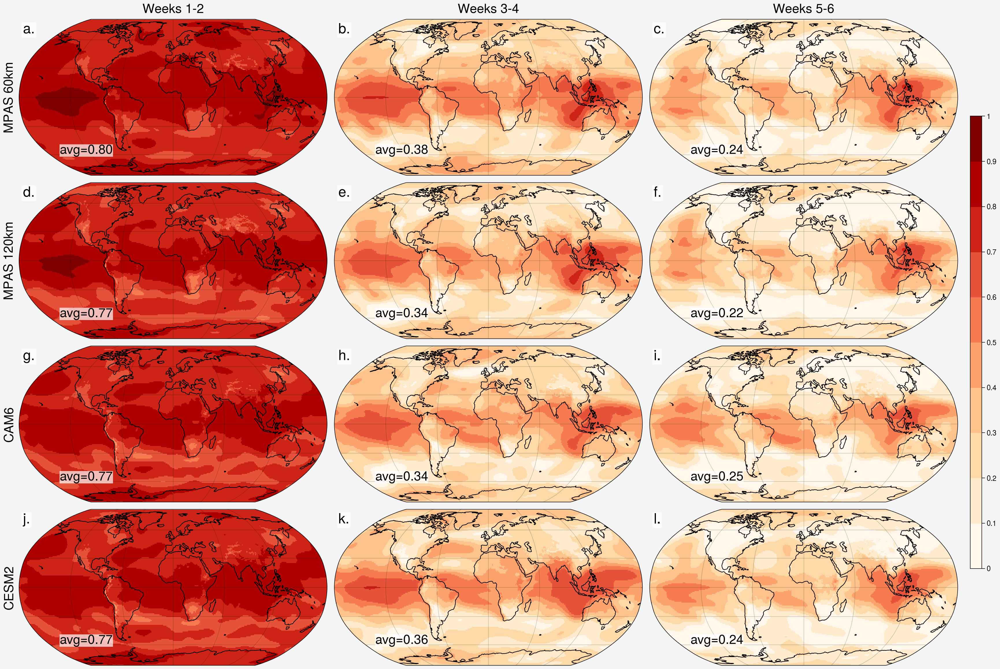

In [12]:
ncols = met_all[variable[0]].shape[1]; nrows = met_all[variable[0]].shape[0]
for vv in variable:
    print(vv)
    metric_settings = plot_settings.get(metric,{})
    pset = metric_settings.get(vv,metric_settings.get("default",{}))
    leadlab = [f"Weeks 1-2",f"Weeks 3-4",f"Weeks 5-6"]
    if domain == "global":
        fig = uplt.figure(axwidth=5.33,hspace=1.0,wspace=1.0,share=0)
        axs = fig.subplots(ncols=ncols,nrows=nrows,space=0,proj="robin",proj_kw={"lon0": 0.0})
    else:
        fig = uplt.figure(axwidth=4.5,hspace=1.0,wspace=1.0,share=0) #hspace = 1.2 if you want abc labels
        axs = fig.subplots(ncols=ncols,nrows=nrows,space=0,proj="aea",proj_kw={"lon0": 247.5, "lat0": 45})
    aa = 0
    axs.format(abc="a.",abcloc="ul",abcweight="normal",fontsize=16,
               abc_kw={"bbox": {"facecolor": "white","alpha": 0.7,"edgecolor": "none","pad": 1.5}})

    for pp in models:
        for mm in met_all.lead:
            cont = axs[aa].pcolormesh(met_all.lon,met_all.lat,met_all[vv].sel(model=pp,lead=mm),cmap=pset.get("cmap"),
                                      vmin=pset.get("vmin"),vmax=pset.get("vmax"),transform=ccrs.PlateCarree())
            if domain == "namerica":
                axs[aa].set_extent([210,295,15,72])
            axs[aa].coastlines("110m",linewidth=0.8)
            axs[aa].gridlines(crs=ccrs.PlateCarree(),x_inline=False,y_inline=False,linewidth=0.2,color='k',alpha=0.3)
            axs[aa].text(0.132,0.12,f"avg={weight[vv].sel(model=pp, lead=mm).values.item():.2f}",ha='left',va='bottom',transform=axs[aa].transAxes,
                         fontsize=16,bbox=dict(facecolor='white',alpha=0.7,edgecolor='none',boxstyle="round,pad=0.01"))
            if aa < ncols:
              axs[aa].text(0.5,1.1,leadlab[aa],va="top",ha="center",rotation="horizontal",
                           rotation_mode="anchor",transform=axs[aa].transAxes,fontsize=16)
            if aa % ncols == 0:
              label = modeln.get(pp, pp)
              axs[aa].text(-0.05,0.5,label,va="top",ha="center",rotation="vertical",
                           rotation_mode="anchor",transform=axs[aa].transAxes,fontsize=16)
            aa += 1
    fig.subplots_adjust(right=0.85)
    fig.colorbar(cont,loc="r",shrink=0.7,label="")
    if savefig=="yes":
        plt.savefig(f"{plotdir}{metric.upper()}_{vv}_{domain}_{season}.jpg",dpi=300,bbox_inches="tight")

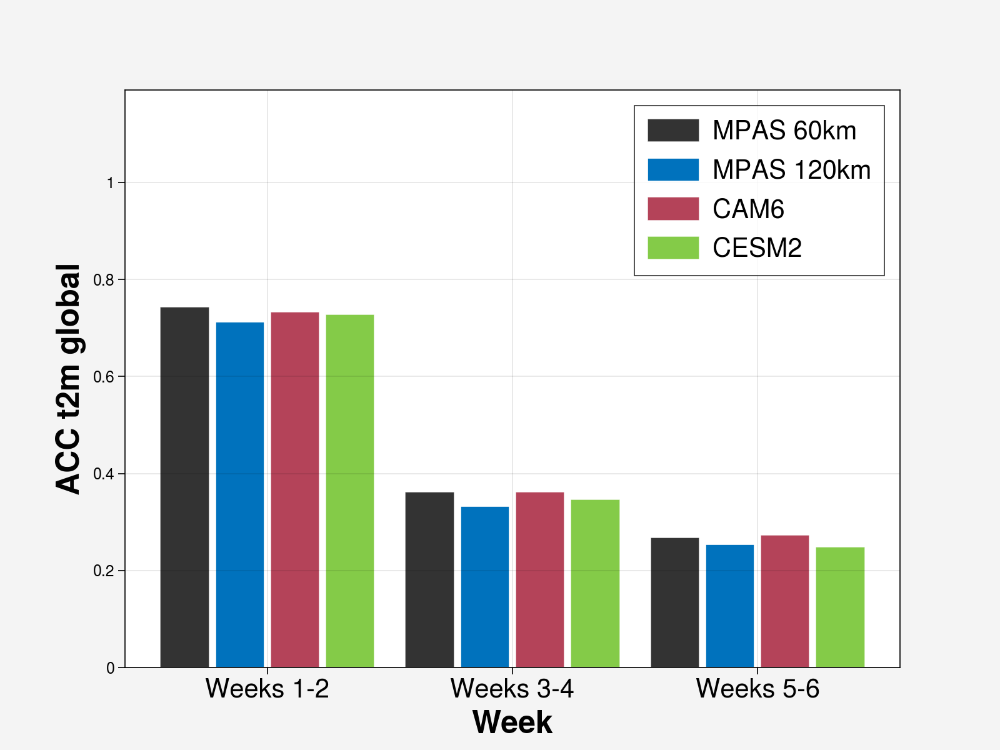

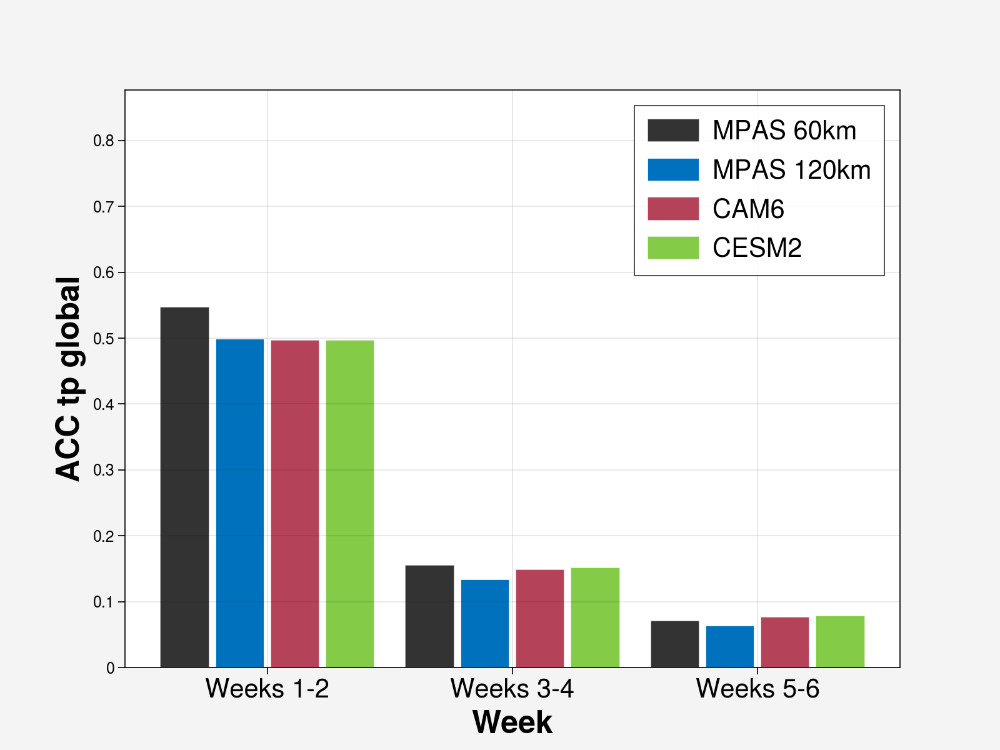

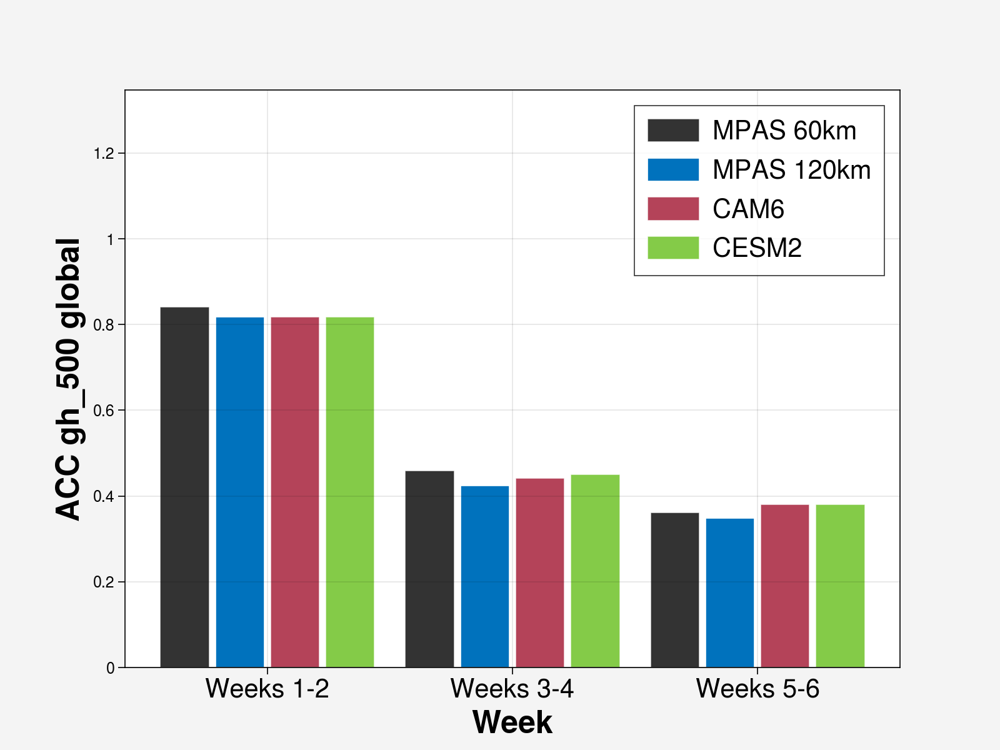

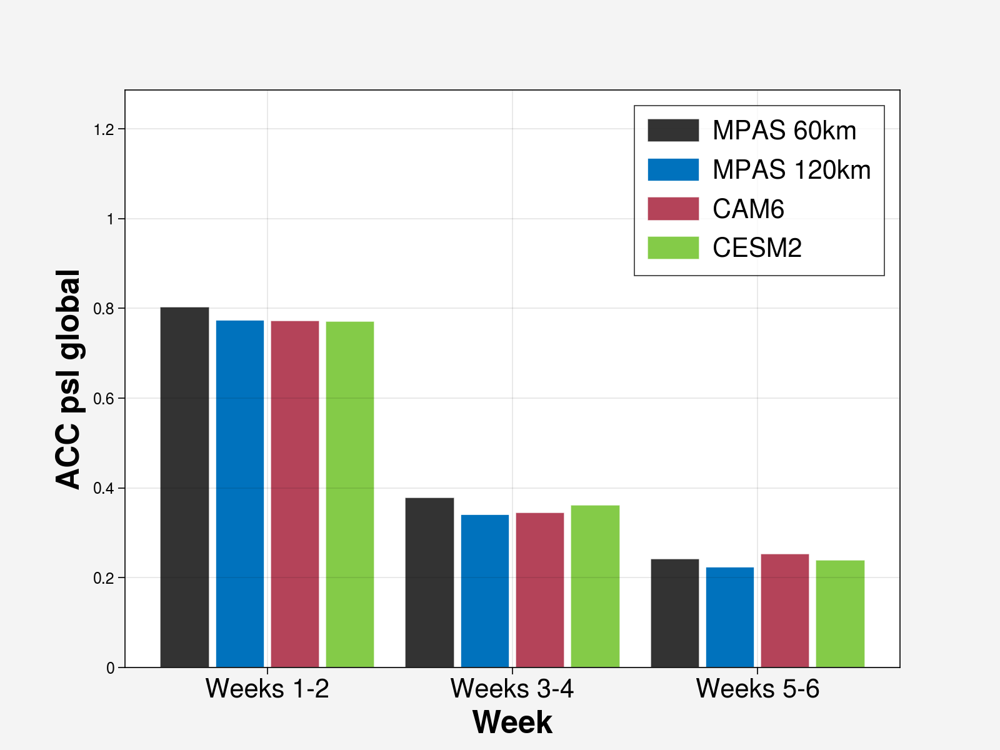

In [13]:
for vv in variable:
    n_models = len(models)
    barWidth = 0.8/n_models
    gap = 0.025

    colors = ["black",(0,0.4470,0.7410),(0.6350,0.0780,0.1840),(0.4,0.75,0.1)][-n_models:]
    alphas = [0.8,1.0,0.8,0.8][-n_models:]

    plt.figure(figsize=(8,6))
    for i in range(n_models):
        rw = [x+(i*(barWidth+gap)) for x in range(3)]
        plt.bar(rw,weight[vv].sel(model=models[i]),width=barWidth,color=colors[i],
                edgecolor="white",alpha=alphas[i],label=modeln[models[i]])

    ymin = weight[vv].min()*1.6 if weight[vv].min() < 0. else 0.0
    ymax = weight[vv].max()*1.6 if weight[vv].max() > 0. else weight[vv].max()*0.4
    legloc = "lower right" if weight[vv].max() < 0. else "upper right"

    tick_shift = ((n_models-1)*(barWidth+gap))/2
    plt.xticks([r+tick_shift for r in range(3)],["Weeks 1-2","Weeks 3-4","Weeks 5-6"],fontsize=15)

    plt.minorticks_off()
    plt.ylim(ymin,ymax)
    plt.ylabel(f"{metric.upper()} {vv} {domain}",fontsize=18,fontweight="bold")
    plt.xlabel("Week",fontsize=18,fontweight="bold")
    plt.legend(borderaxespad=0.6,edgecolor="black",prop={'size': 15},loc=legloc)
    
    if savefig == "yes":
        plt.savefig(f"{plotdir}{metric.upper()}_{vv}_{domain}_{season}_bar.jpg",dpi=300,bbox_inches="tight")

In [14]:
if metric=="rmse":
    for vv in variable:
        if vv=="t2m" or vv=="tp":
            met_all[vv] = met_all[vv].where(met_all.lat>-60.0)
        spr_weight = spr_all.where(spr_all.lat>-60.0).weighted(np.cos(np.deg2rad(spr_all.lat))).mean(("lat","lon"))[vv].compute()
    
        n_models = len(models)
        barWidth = 0.8/n_models
        gap = 0.025
    
        colors = ["black",(0,0.4470,0.7410),(0.6350,0.0780,0.1840),(0.4,0.75,0.1)][-n_models:]
        alphas = [0.8,1.0,0.8,0.8][-n_models:]
    
        plt.figure(figsize=(8,6))
        for i in range(n_models):
            rw = [x+(i*(barWidth+gap)) for x in range(3)]    
            plt.bar(rw,spr_weight.sel(model=models[i]),width=barWidth,color=colors[i],
                    edgecolor="white",alpha=alphas[i],label=modeln[models[i]])
    
        ymin = spr_weight.min()*1.6 if spr_weight.min() < 0. else 0.0
        ymax = spr_weight.max()*1.6 if spr_weight.max() > 0. else spr_weight.max()*0.4
        legloc = "lower right" if spr_weight.max() < 0. else "upper right"
    
        tick_shift = ((n_models-1)*(barWidth+gap))/2
        plt.xticks([r+tick_shift for r in range(3)],["Weeks 1-2","Weeks 3-4","Weeks 5-6"],fontsize=15)
    
        plt.minorticks_off()
        plt.ylim(ymin, ymax)
        plt.ylabel(f"SPREAD {vv} {domain}",fontsize=18,fontweight="bold")
        plt.xlabel("Week",fontsize=18,fontweight="bold")
        plt.legend(borderaxespad=0.6,edgecolor="black",prop={'size': 15},loc=legloc)
        
        if savefig == "yes":
            plt.savefig(f"{plotdir}SPREAD_{vv}_{domain}_{season}_bar.jpg",dpi=300,bbox_inches="tight")